# ASG2 使用者活動、協作關係與時間尺度

用目前建好的八張匿名化 Parquet 分析六種活動的個人頻率、reviewer 與 PR 作者關係，以及開 PR、push、review 的時間差。週邊界依作業使用台灣時間週日 00:00。頻率以可觀察的活動紀錄估計，包含收錄限制。

In [1]:

import gzip
import json
import re
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

root = next(path for path in (Path.cwd(), *Path.cwd().parents)
            if (path / 'data/build_summary.json').is_file())
build = json.loads((root / 'data/build_summary.json').read_text())
start = pd.Timestamp(build['period_utc_inclusive']).tz_localize(None)
end = pd.Timestamp(build['period_utc_exclusive']).tz_localize(None)
test_start = pd.Timestamp('2026-11-22 00:00', tz='Asia/Taipei').tz_convert('UTC').tz_localize(None)
assert end <= test_start
tables = {name: pd.read_parquet(root / 'data/processed/db' / f'{name}.parquet')
          for name in build['tables']}
assert all(len(tables[name]) == n for name, n in build['tables'].items())
users = tables['Users']
cohort_ids = pd.Index([int(line) for line in (root / 'scripts/cohort.txt').read_text().splitlines()],
                      name='github_user_id')
cohort_node_ids = users.loc[users['is_cohort'], 'user_id']
week = pd.Timedelta(days=7)
complete_weeks = pd.date_range(end=test_start, periods=(test_start - start) // week + 1, freq='7D')
complete_weeks = complete_weeks[complete_weeks + week <= end]
print(f'資料區間 UTC {start} 至 {end}（不含）')
print(f'{len(cohort_ids):,} 位 cohort 使用者，{len(complete_weeks)} 個與正式測試週對齊的完整歷史週')


資料區間 UTC 2026-10-01 00:00:00 至 2026-11-18 00:00:00（不含）
9,000 位 cohort 使用者，6 個與正式測試週對齊的完整歷史週


## 1. 個人活動頻率

沿用初探 Notebook 的事件定義。開 PR／issue 用建立時間，review 用提交時間，另用 row time 判斷當時是否已看得到。每種活動列出兩個分母：全部 cohort 的每人每週計數（含 0），以及該類活動在該週至少一次的使用者週。p99 是第 99 百分位，使用 pandas 的線性插值。

In [2]:

definitions = {
    'open_pr': ('PullRequests', 'author_id', 'created_at', 'first_seen_at'),
    'open_issue': ('Issues', 'author_id', 'created_at', 'first_seen_at'),
    'issue_comment': ('IssueComments', 'author_id', 'created_at', 'created_at'),
    'pr_review': ('PRReviews', 'reviewer_id', 'submitted_at', 'first_seen_at'),
    'pr_review_comment': ('PRReviewComments', 'author_id', 'created_at', 'created_at'),
    'push': ('Pushes', 'user_id', 'created_at', 'created_at'),
}
parts = []
for kind, (table, actor, occurs, available) in definitions.items():
    source = tables[table]
    if kind == 'open_issue':
        source = source.loc[source['is_pull_request'].eq(False).fillna(False)]
    records = pd.DataFrame({'user_id': source[actor], 'repo_id': source['repo_id'],
                            'event_time': source[occurs], 'row_time': source[available]})
    records = records.loc[records['user_id'].isin(cohort_node_ids)
                          & records['event_time'].ge(start)
                          & records['event_time'].lt(end)
                          & records['row_time'].lt(end)].copy()
    parts.append(records.assign(activity=kind))
events = pd.concat(parts, ignore_index=True).merge(
    users[['user_id', 'github_user_id']], on='user_id', validate='many_to_one')
def count_by_user(records):
    return (records.groupby(['github_user_id', 'activity']).size().unstack(fill_value=0)
            .reindex(index=cohort_ids, columns=list(definitions), fill_value=0)
            .fillna(0).astype(int))
weekly = pd.concat({
    cutoff: count_by_user(events.loc[events['event_time'].ge(cutoff)
                                      & events['event_time'].lt(cutoff + week)
                                      & events['row_time'].lt(cutoff + week)])
    for cutoff in complete_weeks
}, names=['week_start_utc'])
weekly['any_activity'] = weekly.sum(axis=1)

def frequency_summary(counts):
    return pd.DataFrame.from_dict({
        name: {'positive_pct': 100 * values.gt(0).mean(),
               'median': values.median(), 'p99': values.quantile(.99),
               'active_median': values[values.gt(0)].median(),
               'active_p99': values[values.gt(0)].quantile(.99),
               'max': values.max()}
        for name, values in counts.items()
    }, orient='index').round(2)

display(frequency_summary(weekly))
display(weekly.drop(columns='any_activity').gt(0).groupby(level='week_start_utc').mean().mul(100).round(2))

per_user = count_by_user(events).sum(axis=1)
print(f'全期至少有一項活動的使用者：{per_user.gt(0).sum():,} / {len(per_user):,}')
print(f'全期每人活動數，全 cohort 中位數 {per_user.median():g}，p99 {per_user.quantile(.99):g}；'
      f'至少一次活動者中位數 {per_user[per_user.gt(0)].median():g}，'
      f'p99 {per_user[per_user.gt(0)].quantile(.99):g}。')


,positive_pct,median,p99,active_median,active_p99,max
open_pr,4.20,0.0,2.0,1.0,8.00,91
open_issue,2.34,0.0,2.0,1.0,36.00,74
issue_comment,2.68,0.0,1.0,1.0,13.00,26
pr_review,2.90,0.0,1.0,1.0,13.00,46
pr_review_comment,1.41,0.0,1.0,1.0,9.40,24
push,14.32,0.0,12.0,2.0,41.00,314
any_activity,18.73,0.0,16.0,2.0,49.86,326


activity,open_pr,open_issue,issue_comment,pr_review,pr_review_comment,push
week_start_utc,,,,,,
2026-10-03 16:00:00,5.26,2.77,3.54,3.48,1.71,24.27
2026-10-10 16:00:00,4.37,2.62,2.59,3.11,2.08,23.67
2026-10-17 16:00:00,3.87,2.50,2.36,2.50,1.90,20.53
2026-10-24 16:00:00,3.70,1.97,2.49,2.66,0.83,11.21
2026-10-31 16:00:00,4.26,2.18,2.84,3.06,1.17,3.14
2026-11-07 16:00:00,3.76,2.02,2.28,2.59,0.77,3.08


全期至少有一項活動的使用者：4,205 / 9,000
全期每人活動數，全 cohort 中位數 0，p99 105.01；至少一次活動者中位數 4，p99 188.84。


## 2. reviewer → PR 作者，以及同 repo 活動

以 `PRReviews.pr_id` 接 `PullRequests.pr_id`，保留已知作者、已知 reviewer 且兩者不同的列。作者可在 cohort 之外。這裡算的是已觀察到的連線，reviewer 未提交或來源沒收錄時就沒有這條邊。另一個表用「同 repo 出現過」衡量較寬的關聯，以觀察把同 repo 的人兩兩連邊有多密。

In [3]:

pr = tables['PullRequests'][['pr_id', 'author_id', 'created_at', 'first_seen_at', 'head_repo_id', 'head_sha']].rename(
    columns={'created_at': 'opened_at', 'first_seen_at': 'pr_row_time'})
reviews = tables['PRReviews'][['pr_id', 'reviewer_id', 'submitted_at', 'first_seen_at', 'commit_id']].rename(
    columns={'first_seen_at': 'review_row_time'})
reviews = reviews.loc[reviews['submitted_at'].ge(start) & reviews['submitted_at'].lt(end)
                      & reviews['review_row_time'].lt(end)]
joined = reviews.merge(pr, on='pr_id', how='left', validate='many_to_one')
known = joined.loc[joined[['reviewer_id', 'author_id']].notna().all(axis=1)].copy()
different = known.loc[known['reviewer_id'].ne(known['author_id'])].copy()
pairs = different.groupby(['reviewer_id', 'author_id']).size().rename('reviews')
per_reviewer = pairs.groupby(level='reviewer_id').size()
per_author = pairs.groupby(level='author_id').size()
repo_users = events.groupby('repo_id')['user_id'].nunique()
large_repo = int(repo_users.max())
print(f'實際觀察到的 reviews：{len(reviews):,}；兩端已知：{len(known):,}；跨人：{len(different):,}')
print(f'跨人 reviewers {different["reviewer_id"].nunique():,} 位，作者 {different["author_id"].nunique():,} 位。')
print(f'兩端皆為 cohort 的跨人 reviews：{(different["author_id"].isin(cohort_node_ids) & different["reviewer_id"].isin(cohort_node_ids)).sum():,} 筆。')
display(pairs.describe(percentiles=[.5, .9, .99]).to_frame().round(2))
print(f'有向 reviewer–作者配對 {len(pairs):,} 對；其中至少兩次 {pairs.ge(2).sum():,} 對（{100*pairs.ge(2).mean():.1f}%）。')
display(pd.DataFrame.from_dict({
            'authors_per_reviewer': per_reviewer.describe(percentiles=[.5, .99]),
            'reviewers_per_author': per_author.describe(percentiles=[.5, .99]),
            'cohort_actors_per_repo': repo_users.describe(percentiles=[.5, .99]),
        }, orient='index')[['count', '50%', '99%', 'max']].round(2))
print(f'最大 repo {large_repo:,} 位 cohort 活動者，完全兩兩連邊會產生 {large_repo*(large_repo-1)//2:,} 對。')


實際觀察到的 reviews：3,561；兩端已知：136；跨人：15
跨人 reviewers 14 位，作者 15 位。
兩端皆為 cohort 的跨人 reviews：1 筆。


,reviews
count,15.0
mean,1.0
std,0.0
min,1.0
50%,1.0
90%,1.0
99%,1.0
max,1.0


有向 reviewer–作者配對 15 對；其中至少兩次 0 對（0.0%）。


,count,50%,99%,max
authors_per_reviewer,14.0,1.0,1.87,2.0
reviewers_per_author,15.0,1.0,1.00,1.0
cohort_actors_per_repo,12120.0,1.0,2.00,13.0


最大 repo 13 位 cohort 活動者，完全兩兩連邊會產生 78 對。


## 3. 開 PR → 第一次觀察到的他人 review

分布採用同一支 PR 上的第一筆可觀察的他人 review。PR 必須在這段期間開啟，並保留至少七天的觀測空間。分位數只計入有觀察到 review 的 PR，因此不能用來推估所有 PR 被 review 的機率。比較 ≤24 小時和台灣同一日，可以看到日界線會如何切斷短時間的事件順序。

Push 的 proxy 取同一 PR 作者在該 PR 的 head repo、review 提交前最近一次已觀察的 push。Pushes 表未存該次 push 的 SHA，附近的 push 可能屬於別的分支或 commit。review 的 commit ID 可以比對 PR 首次記錄的 head SHA，這仍然不能認定是哪一筆 push。

In [4]:

opened = pr.loc[pr['author_id'].notna() & pr['opened_at'].ge(start)
                & pr['opened_at'].lt(end - week) & pr['pr_row_time'].lt(end)]
ordered = different.loc[different['pr_id'].isin(opened['pr_id'])
                        & different['submitted_at'].ge(different['opened_at'])].copy()
first = ordered.sort_values('submitted_at').drop_duplicates('pr_id').copy()
first['hours'] = (first['submitted_at'] - first['opened_at']).dt.total_seconds() / 3600

def lag_summary(hours):
    return pd.Series({'n': len(hours), 'p50_hours': hours.median(),
                      'p90_hours': hours.quantile(.90), 'p99_hours': hours.quantile(.99),
                      'within_1h_pct': 100 * hours.le(1).mean(),
                      'within_6h_pct': 100 * hours.le(6).mean(),
                      'within_24h_pct': 100 * hours.le(24).mean(),
                      'within_7d_pct': 100 * hours.le(168).mean()})

def period_key(times, period):
    local_naive = times.dt.tz_localize('UTC').dt.tz_convert('Asia/Taipei').dt.tz_localize(None)
    if period == 'hour':
        return local_naive.dt.floor('h')
    day = local_naive.dt.floor('D')
    if period == 'day':
        return day
    return day - pd.to_timedelta((day.dt.dayofweek + 1) % 7, unit='D')

def boundary_summary(left, right):
    return pd.Series({f'same_{period}_pct': 100 * period_key(left, period).eq(period_key(right, period)).mean()
                      for period in ['hour', 'day', 'week']})

print(f'開啟時間和作者已知、且至少有七天觀測空間的 PR：{len(opened):,}。')
print(f'其中能配對到在開啟之後的第一筆已觀察他人 review：{len(first):,}。')
display(pd.concat([lag_summary(first['hours']),
                  boundary_summary(first['opened_at'], first['submitted_at'])]).round(2).to_frame('PR → first review'))

repos = tables['Repositories'][['repo_id', 'github_repo_id']].rename(columns={'repo_id': 'head_repo_row'})
with_head = first.merge(repos, left_on='head_repo_id', right_on='github_repo_id', how='left', validate='many_to_one')
eligible = with_head.loc[with_head['head_repo_row'].notna() & with_head['author_id'].isin(cohort_node_ids)].copy()
eligible['author_id'] = eligible['author_id'].astype('int64')
eligible['head_repo_row'] = eligible['head_repo_row'].astype('int64')
pushes = tables['Pushes'][['user_id', 'repo_id', 'created_at']].rename(
    columns={'user_id': 'author_id', 'repo_id': 'head_repo_row', 'created_at': 'push_at'}).dropna()
pushes = pushes.astype({'author_id': 'int64', 'head_repo_row': 'int64'})
matched = pd.merge_asof(eligible.sort_values('submitted_at'), pushes.sort_values('push_at'),
                        left_on='submitted_at', right_on='push_at',
                        by=['author_id', 'head_repo_row'], direction='backward', allow_exact_matches=False)
proxy = matched.loc[matched['push_at'].notna()].copy()
proxy['hours'] = (proxy['submitted_at'] - proxy['push_at']).dt.total_seconds() / 3600
has_sha = first['commit_id'].notna() & first['head_sha'].notna()
print(f'{len(eligible):,} 筆首筆 review 具有 cohort 作者和可辨識的 head repo，其中 {len(proxy):,} 筆有前置 push proxy。')
print(f'首筆 review 中，兩邊 SHA 皆有值 {has_sha.sum():,} 筆，等於 PR 初始 head SHA '
      f'{first.loc[has_sha, "commit_id"].eq(first.loc[has_sha, "head_sha"]).sum():,} 筆。')
display(pd.concat([lag_summary(proxy['hours']),
                  boundary_summary(proxy['push_at'], proxy['submitted_at'])]).round(2).to_frame('prior same-repo push → first review'))


開啟時間和作者已知、且至少有七天觀測空間的 PR：4,104。
其中能配對到在開啟之後的第一筆已觀察他人 review：10。


,PR → first review
n,10.00
p50_hours,49.92
p90_hours,207.44
p99_hours,540.46
within_1h_pct,10.00
within_6h_pct,30.00
within_24h_pct,40.00
within_7d_pct,90.00
same_hour_pct,10.00
same_day_pct,40.00


3 筆首筆 review 具有 cohort 作者和可辨識的 head repo，其中 3 筆有前置 push proxy。
首筆 review 中，兩邊 SHA 皆有值 10 筆，等於 PR 初始 head SHA 7 筆。


,prior same-repo push → first review
n,3.00
p50_hours,193.81
p90_hours,442.59
p99_hours,498.57
within_1h_pct,0.00
within_6h_pct,0.00
within_24h_pct,33.33
within_7d_pct,33.33
same_hour_pct,0.00
same_day_pct,33.33


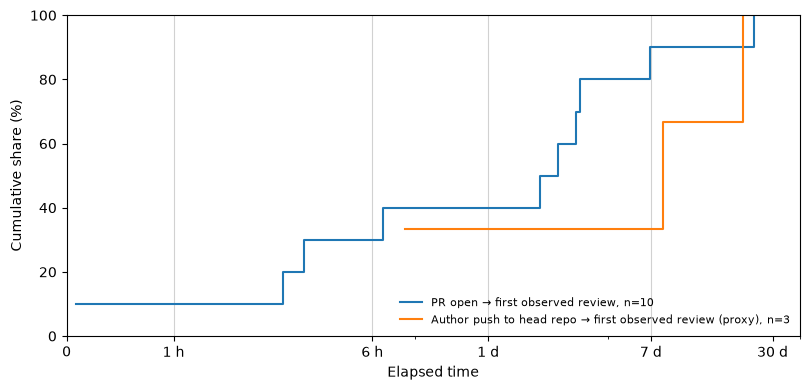

In [5]:

fig, ax = plt.subplots(figsize=(8.2, 4.0))
for frame, label in [(first, 'PR open → first observed review'),
                     (proxy, 'Author push to head repo → first observed review (proxy)')]:
    hours = np.sort(frame['hours'].to_numpy())
    cumulative = np.arange(1, len(hours) + 1) / len(hours)
    ax.step(hours, cumulative * 100, where='post', label=f'{label}, n={len(hours):,}')
for mark in [1, 6, 24, 168]:
    ax.axvline(mark, color='0.82', linewidth=0.8, zorder=0)
ax.set(xscale='symlog', xlim=(0, 1000), ylim=(0, 100), xlabel='Elapsed time',
       ylabel='Cumulative share (%)')
ax.set_xticks([0, 1, 6, 24, 168, 720], ['0', '1 h', '6 h', '1 d', '7 d', '30 d'])
ax.legend(loc='lower right', frameon=False, fontsize=8)
fig.tight_layout()
plt.show()


## 4. 其他可觀察的協作，以及同一人的活動間隔

PR review comment 與 PR 對話留言各自透過外鍵連回 PR。只用作者已知、留言者已知且兩者不同的紀錄，每種留言各取每支 PR 最早一筆，用與第一筆 review 相同的 PR 納入規則。「同一人的相鄰活動」則按時間排序，全期至少兩筆者才會貢獻間隔。這裡每個觀察到的間隔權重相同，活躍者貢獻的間隔較多。

In [6]:

code_comments = tables['PRReviewComments'][['pr_id', 'author_id', 'created_at']].rename(
    columns={'author_id': 'actor_id', 'created_at': 'acted_at'})
conversation_comments = (tables['IssueComments'][['issue_id', 'author_id', 'created_at']]
    .merge(tables['Issues'][['issue_id', 'pull_request_id']], on='issue_id', validate='many_to_one')
    .rename(columns={'pull_request_id': 'pr_id', 'author_id': 'actor_id', 'created_at': 'acted_at'}))
interaction_counts = {}
interaction_lags = {}
for name, comments in [('pr_review_comment', code_comments), ('pr_conversation_comment', conversation_comments)]:
    comments = comments.loc[comments['pr_id'].notna() & comments['acted_at'].ge(start) & comments['acted_at'].lt(end)]
    linked = comments.merge(pr[['pr_id', 'author_id', 'opened_at']], on='pr_id', validate='many_to_one')
    linked = linked.loc[linked[['actor_id', 'author_id']].notna().all(axis=1)
                        & linked['actor_id'].ne(linked['author_id'])]
    comment_pairs = linked.groupby(['actor_id', 'author_id']).size()
    interaction_counts[name] = {'cross_user_events': len(linked), 'pairs': len(comment_pairs),
                                'repeated_pairs': int(comment_pairs.ge(2).sum())}
    earliest = (linked.loc[linked['pr_id'].isin(opened['pr_id'])
                           & linked['acted_at'].ge(linked['opened_at'])]
                .sort_values('acted_at').drop_duplicates('pr_id'))
    hours = (earliest['acted_at'] - earliest['opened_at']).dt.total_seconds() / 3600
    interaction_lags[name] = pd.concat([lag_summary(hours), boundary_summary(earliest['opened_at'], earliest['acted_at'])])
display(pd.DataFrame.from_dict(interaction_counts, orient='index'))
display(pd.DataFrame(interaction_lags).T.round(2))

def consecutive_event_lag(records):
    ordered_events = records.sort_values(['user_id', 'event_time'])
    times = ordered_events['event_time']
    previous = ordered_events.groupby('user_id')['event_time'].shift()
    matched = previous.notna()
    hours = (times[matched] - previous[matched]).dt.total_seconds() / 3600
    return pd.concat([lag_summary(hours), boundary_summary(previous[matched], times[matched])])

display(pd.DataFrame({
    'all_activities': consecutive_event_lag(events),
    'activities_excluding_push': consecutive_event_lag(events.loc[events['activity'].ne('push')]),
}).T.round(2))


,cross_user_events,pairs,repeated_pairs
pr_review_comment,7,7,0
pr_conversation_comment,19,19,0


,n,p50_hours,p90_hours,p99_hours,within_1h_pct,within_6h_pct,within_24h_pct,within_7d_pct,same_hour_pct,same_day_pct,same_week_pct
pr_review_comment,5.0,46.76,228.92,320.18,0.00,20.0,20.0,80.00,0.00,20.0,80.00
pr_conversation_comment,14.0,21.04,188.32,334.51,35.71,50.0,50.0,78.57,21.43,50.0,64.29


,n,p50_hours,p90_hours,p99_hours,within_1h_pct,within_6h_pct,within_24h_pct,within_7d_pct,same_hour_pct,same_day_pct,same_week_pct
all_activities,58250.0,1.78,92.63,456.36,42.81,63.34,78.19,94.72,31.65,66.94,85.40
activities_excluding_push,16458.0,7.26,174.80,675.19,29.75,48.17,65.33,89.43,23.03,52.98,76.44


## 5. Push 收錄抽查

查看數個 UTC 日期的三個原始小時檔，統計全站頂層 `type` 為 `PushEvent` 的列數。這是來源收錄診斷，與上面只看 cohort 的模型資料分開。小時檔存在仍可能缺少某一類事件。

In [7]:

raw = root / 'data/raw/gharchive'
dates = ['2026-10-14', '2026-10-16', '2026-10-29', '2026-11-10', '2026-11-11']
pattern = re.compile(rb'^\s*\{\s*"id"\s*:\s*"[^"]+"\s*,\s*"type"\s*:\s*"([^"]+)"')

def inspect_hour(date_and_hour):
    day, hour = date_and_hour
    path = raw / f'{day}-{hour}.json.gz'
    rows, pushes = 0, 0
    with gzip.open(path, 'rb') as archive:
        for line in archive:
            event_type = pattern.match(line)
            pushes += (event_type[1] == b'PushEvent') if event_type else (json.loads(line)['type'] == 'PushEvent')
            rows += 1
    return {'date_utc': day, 'hour_utc': hour, 'raw_rows': rows, 'raw_push_events': pushes}

hours = [(day, hour) for day in dates for hour in [4, 12, 20]]
if all((raw / f'{day}-{hour}.json.gz').is_file() for day, hour in hours):
    with ThreadPoolExecutor(max_workers=4) as pool:
        audit = pd.DataFrame(pool.map(inspect_hour, hours))
    display(audit.pivot(index='date_utc', columns='hour_utc', values='raw_push_events'))
else:
    print('目前沒有這組原始小時檔，略過來源抽查。')


hour_utc,4,12,20
date_utc,,,
2026-10-14,68184,77272,0
2026-10-16,0,0,0
2026-10-29,0,0,0
2026-11-10,0,0,0
2026-11-11,0,0,0


## 6. 對建模的含義

- 訓練與驗證維持每人未來七天的六個二元標籤。歷史訊號以原始時間戳保留順序，再做 1／6／24 小時與 7／14 天的計數或近期性特徵。
- 開 PR 和 review 透過 PR ID 配對。push 與 review 的先後以同一作者、同一 head repo 的近鄰事件描述，可作 proxy 並附上適用條件。
- 先比較只用週尺度、加入日尺度、再加入小時與有序互動訊號三組特徵。各組用相同的週切點、同一組七天標籤和評分規則。這份分析只檢查分布與資料品質，哪組 F1 較高要由這個驗證比較決定。
- 每次預測先按 row time 截止，時間差以事件時間計算。push 收錄量明顯變動時，分開報有收錄與來源可疑時段的結果。正式預測跨進測試週後仍只能使用開跑前的歷史。